
 Spot checking: extragalactic_lt20mag_candidates_classified_spot_check_required_n_2.csv (1 objects)
Plotting 314003014107006318...


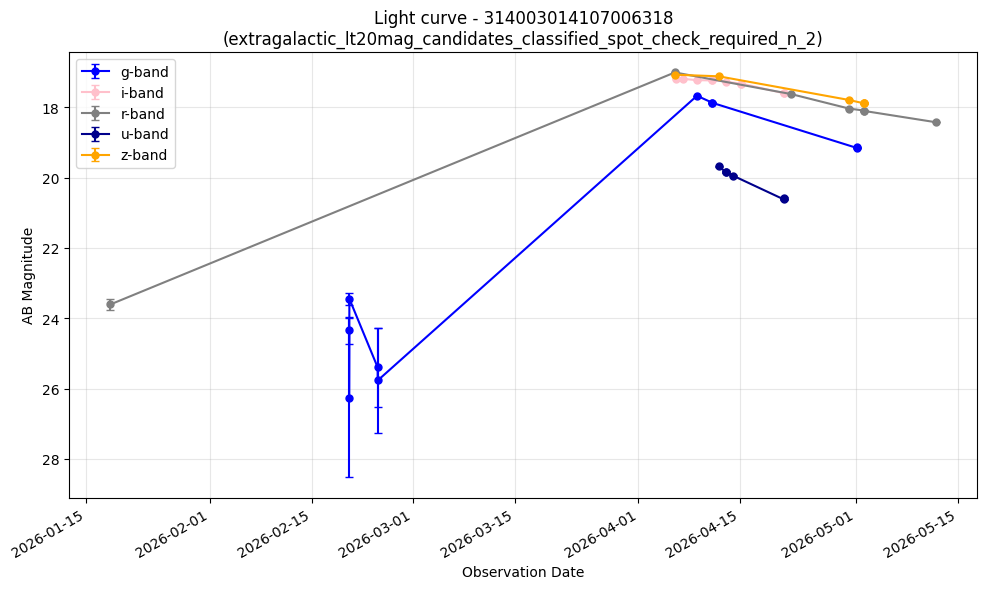


 Spot checking: extragalactic_lt20mag_candidates_classified_spot_check_required_n_1.csv (0 objects)

 Spot checking: extragalactic_new_candidate_classified_spot_check_required_n_2.csv (3 objects)
Plotting 170301167290548441...


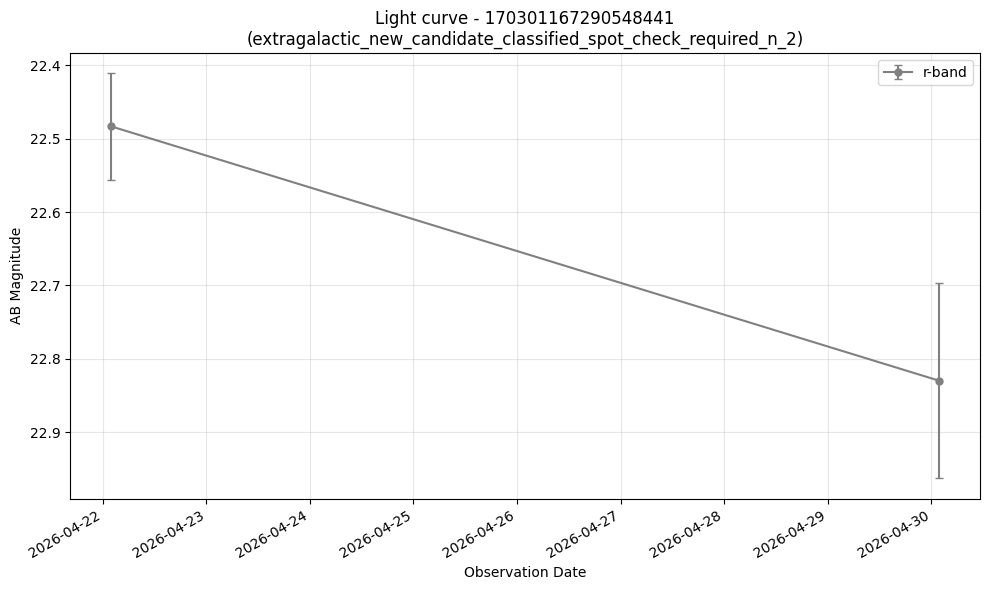

Plotting 170336356481892438...


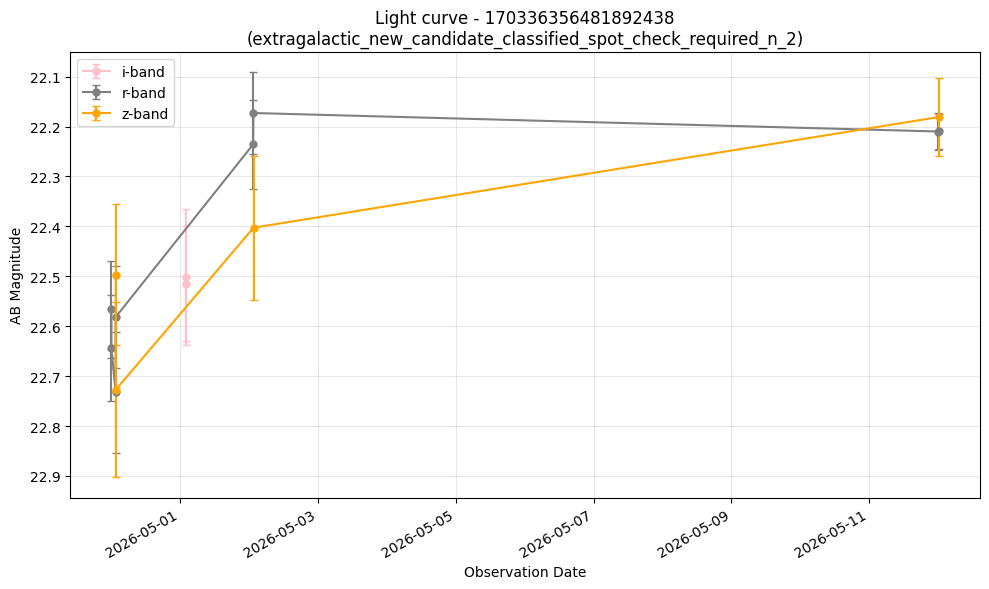

Plotting 170336356503388205...


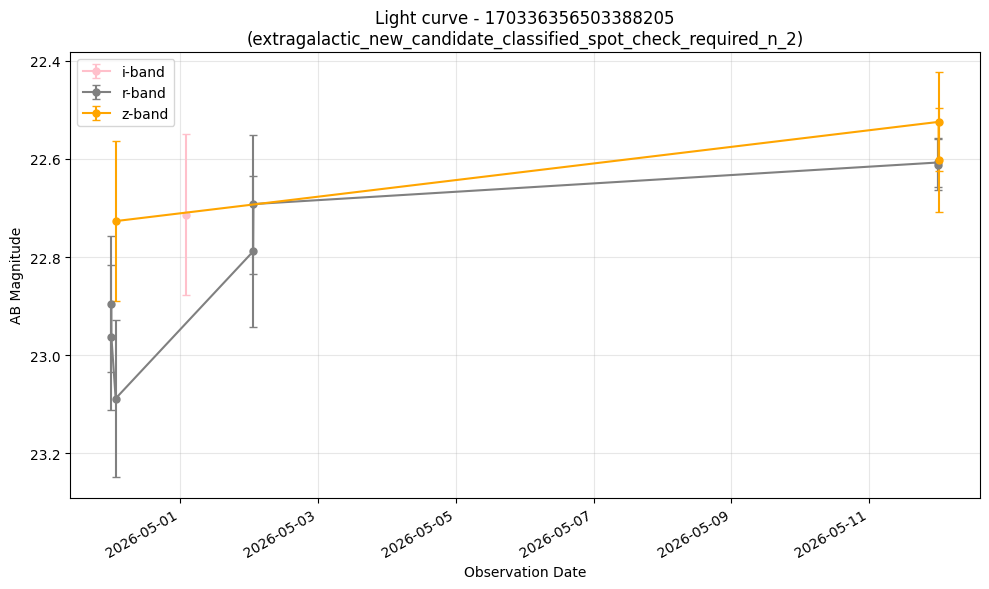


 Spot checking: extragalactic_new_candidate_classified_spot_check_required_n_1.csv (6 objects)
Plotting 170301167209807939...


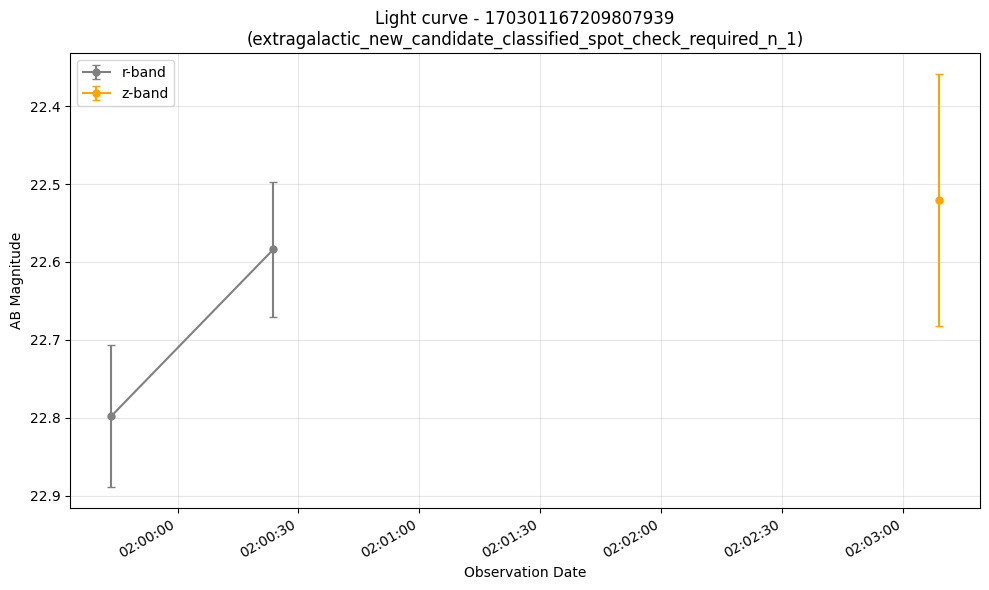

Plotting 170301167243886614...


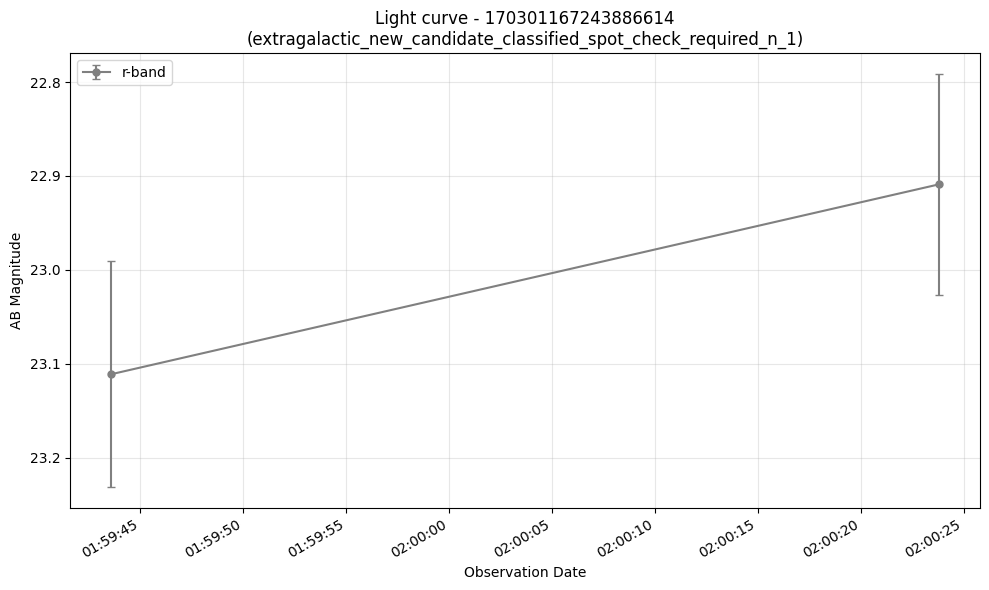

Plotting 170301167288975422...


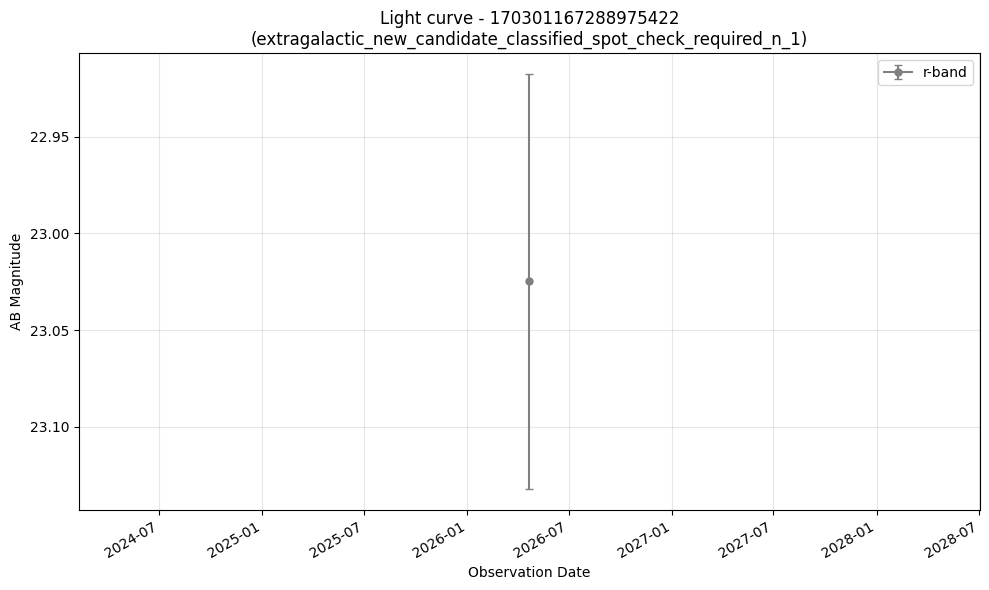

Plotting 170301167279538215...


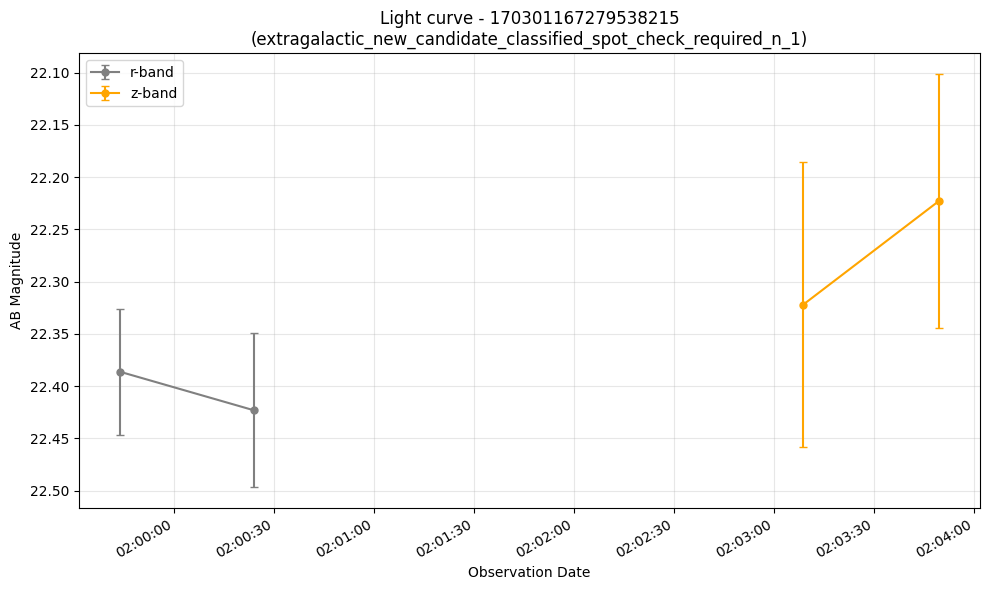

Plotting 170301167475097661...


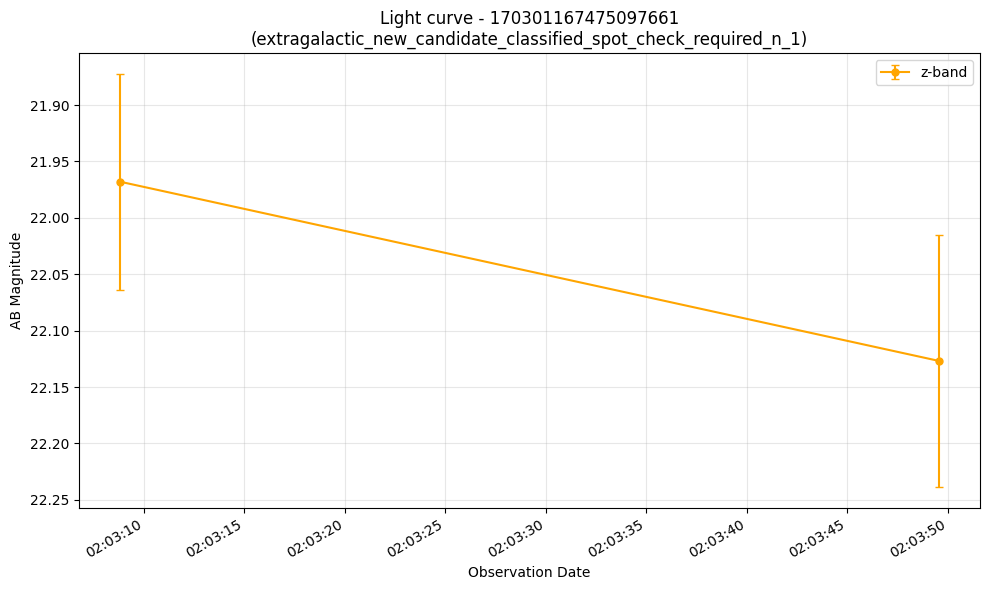

Plotting 170301167343501514...


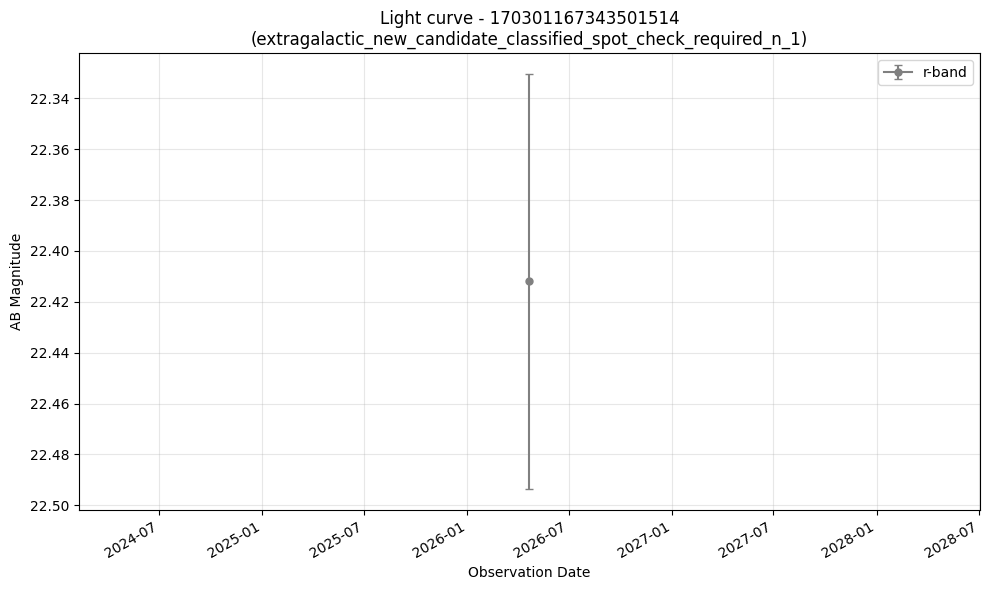


 Spot checking: sn_near_galaxy_candidate_classified_spot_check_required_n_2.csv (10 objects)
Plotting 170028526511063098...


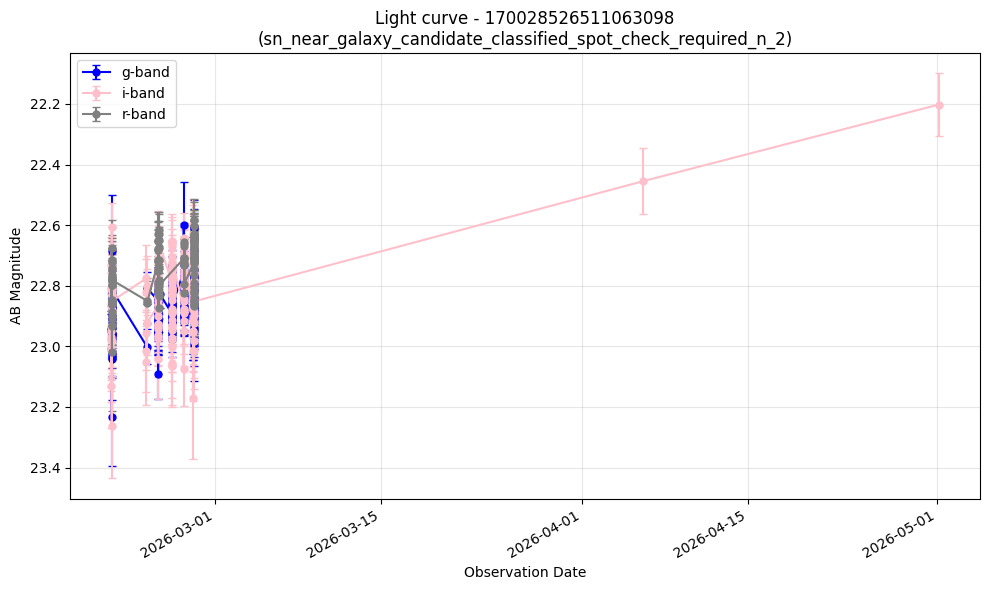

Plotting 170028526517354568...


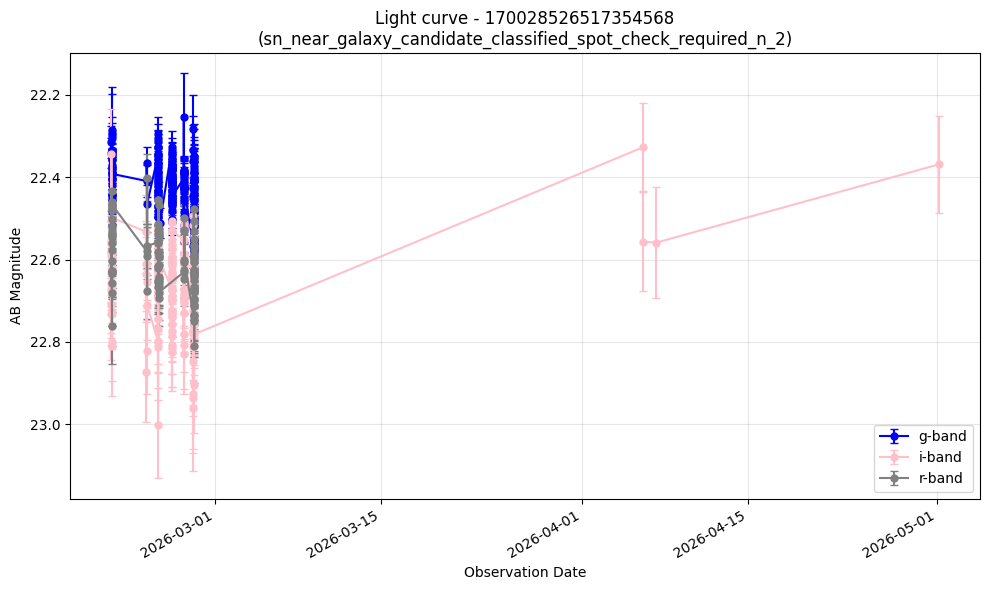

Plotting 170028526533608163...


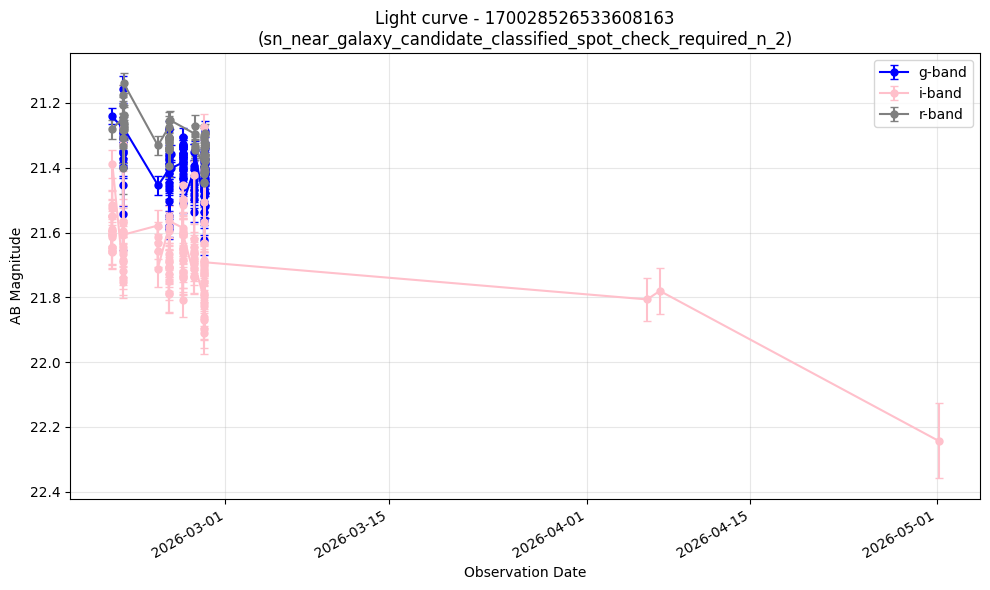

Plotting 170028526535180328...


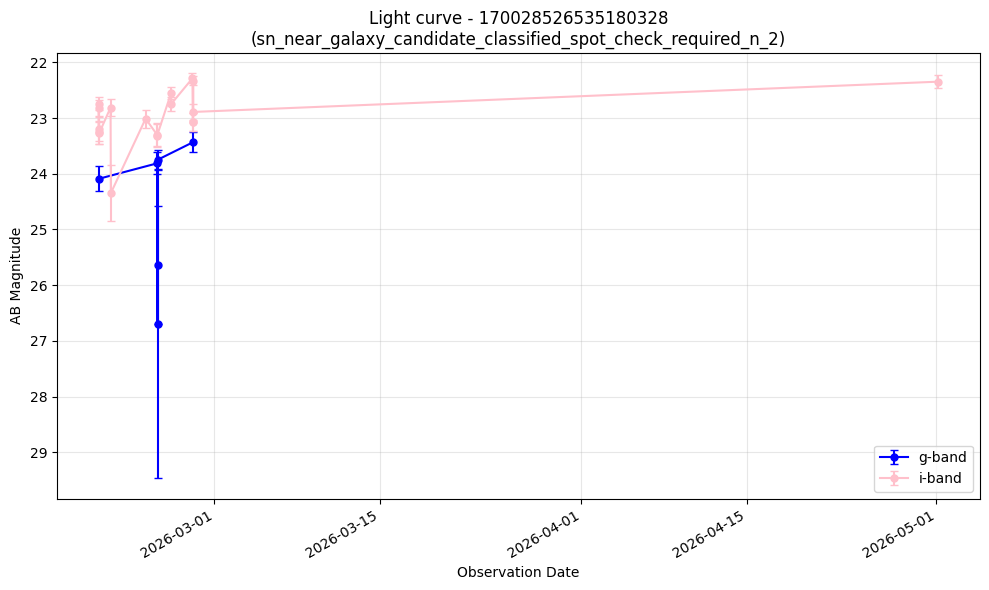

Plotting 170028526800994812...


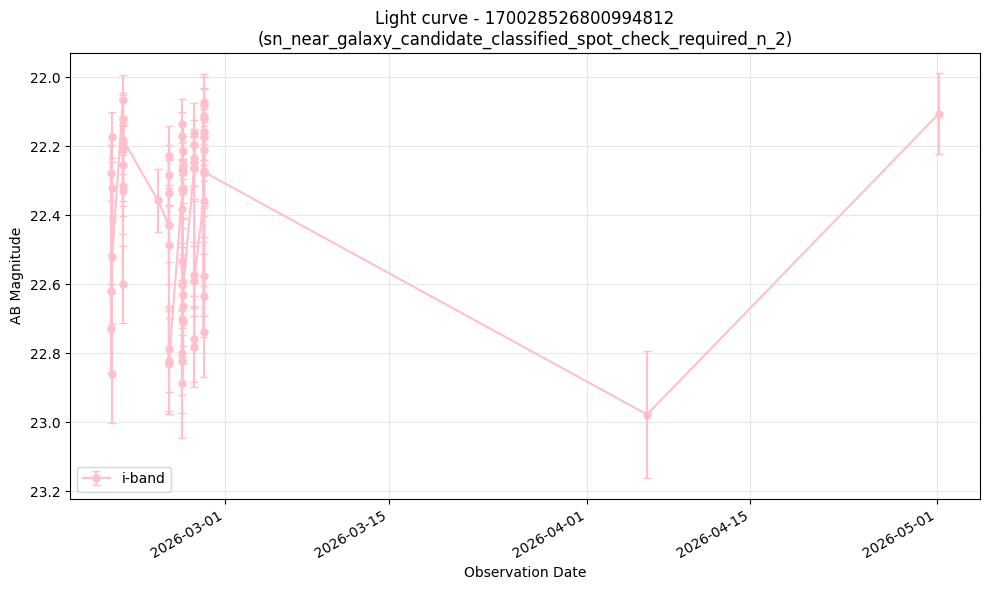

Plotting 170028534042984523...


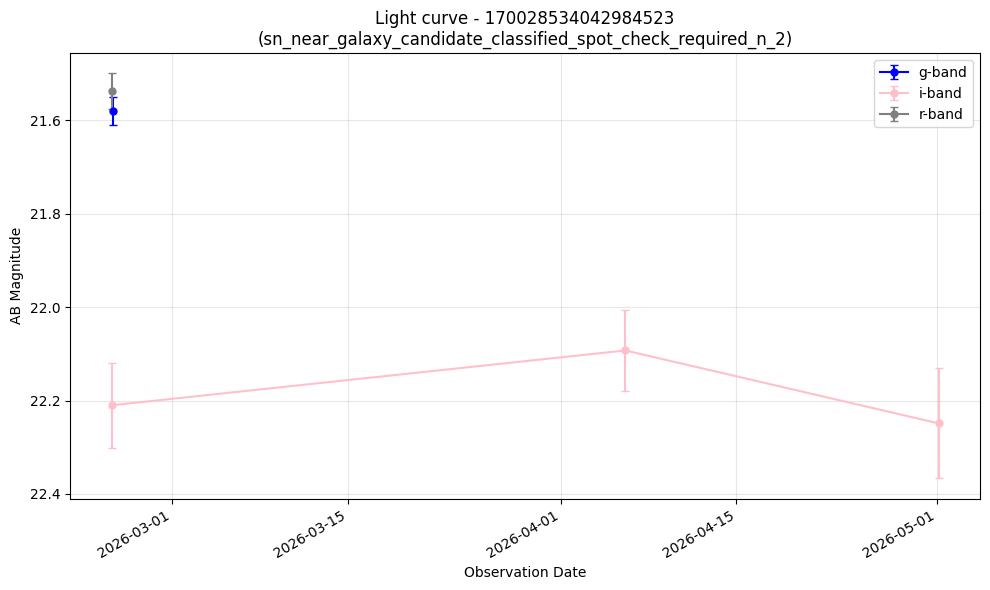

Plotting 313998569462300707...


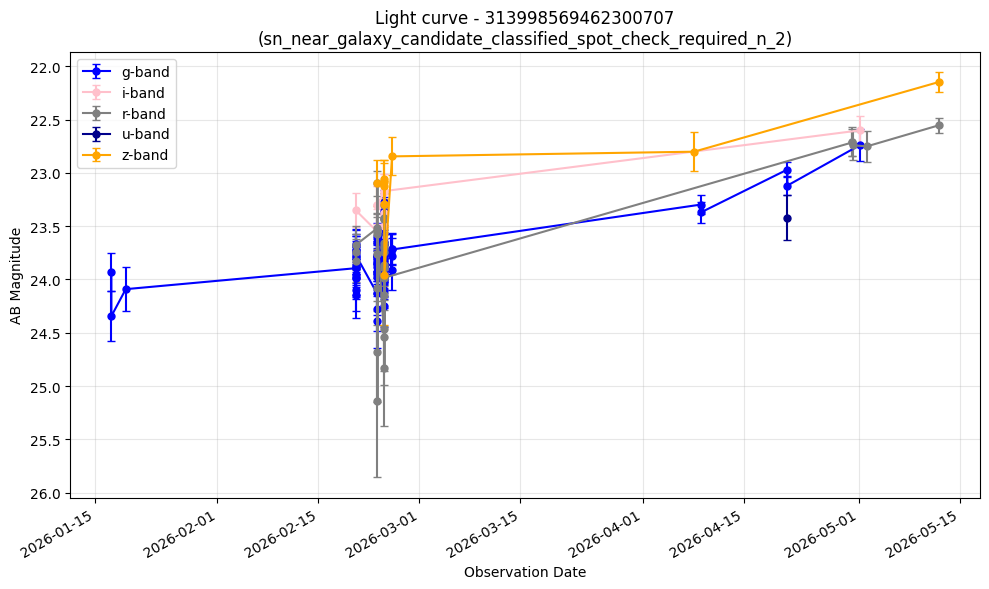

Plotting 313998569623257167...


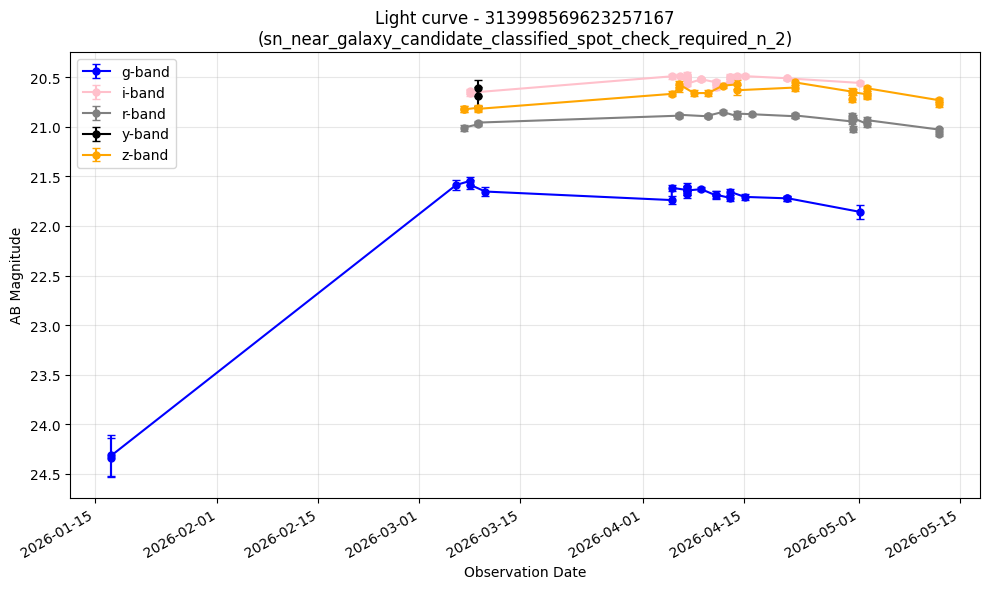

Plotting 314003013678137685...


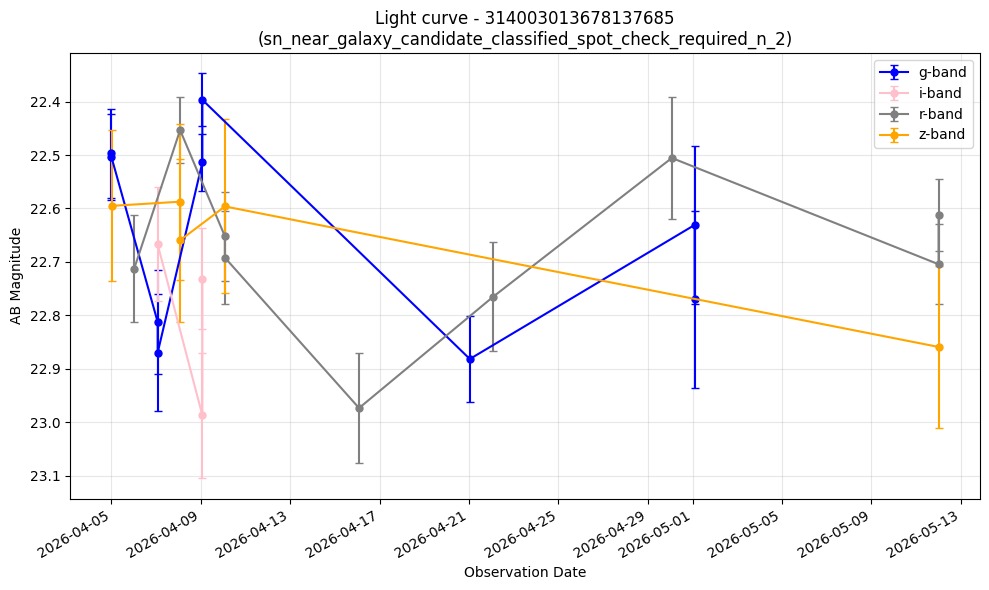

Plotting 314003014420004875...


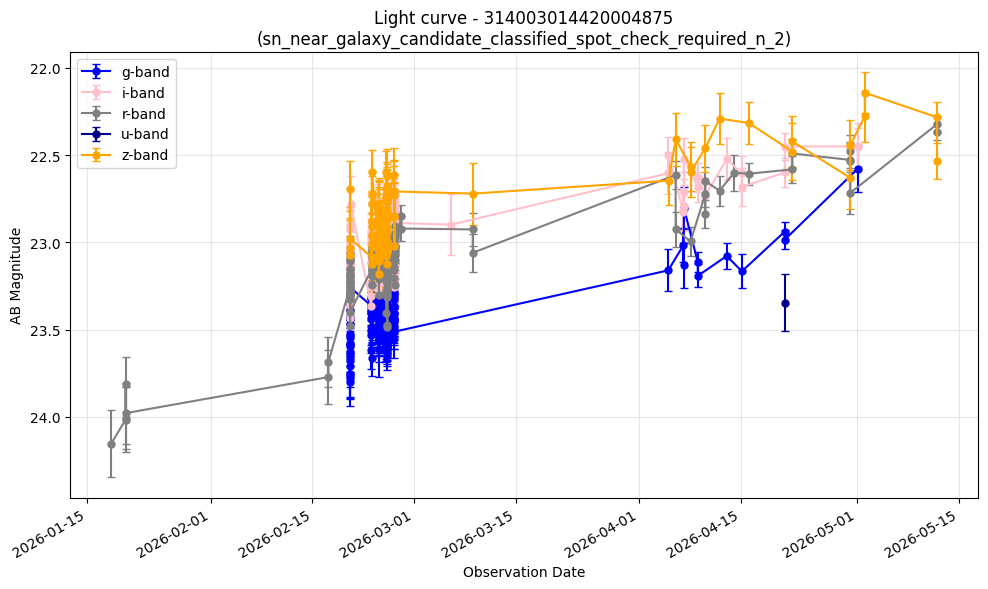


 Spot checking: sn_near_galaxy_candidate_classified_spot_check_required_n_1.csv (0 objects)


In [ ]:
# reads and plots candidates that i need to spot check personally if they don't pass all three classifiers
from pathlib import Path
import pandas as pd
from light_curve_plotter import collect_light_curve_data, lightcurve_plotting

base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Potential_SN_candidates")

csv_files = [base_path / "extragalactic_lt20mag_candidates_classified_spot_check_required_n_2.csv",
             base_path / "extragalactic_lt20mag_candidates_classified_spot_check_required_n_1.csv",
             base_path / "extragalactic_new_candidate_classified_spot_check_required_n_2.csv",
             base_path / "extragalactic_new_candidate_classified_spot_check_required_n_1.csv",
             base_path / "sn_near_galaxy_candidate_classified_spot_check_required_n_2.csv",
             base_path / "sn_near_galaxy_candidate_classified_spot_check_required_n_1.csv"]

for csv_file in csv_files:
    df_candidates = pd.read_csv(csv_file, dtype={"r:diaObjectId":str})
    print (f"\n Spot checking: {csv_file.name} ({len(df_candidates)} objects)")

    for objectID in df_candidates["r:diaObjectId"]:
        print(f"Plotting {objectID}...")
        df_lc = collect_light_curve_data(objectID)
        if df_lc is not None:
            lightcurve_plotting(df_lc, objectID, csv_file.stem)

In [ ]:
# appends confirmed SNe from spot checks to the confirmed SNe CSV taken from the classifier method.
from pathlib import Path
import pandas as pd

base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Confirmed_SN")
confirmed_SN_output = base_path / "confirmed_SN.csv"

high_confidence_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\Potential_SN_candidates\extragalactic_lt20mag_candidates_classified_high_confidence.csv")
high_confidence_SN = pd.read_csv(high_confidence_path, dtype={"r:diaObjectId": str})

# Manually confirmed object that didn't pass three classifiers
manual_confirmed = pd.DataFrame({"r:diaObjectId": ["314003014107006318"]})

# Combine and deduplicate
confirmed_SN = pd.concat([high_confidence_SN, manual_confirmed], ignore_index=True)
confirmed_SN = confirmed_SN.drop_duplicates(subset="r:diaObjectId")

base_path.mkdir(parents=True, exist_ok=True)
confirmed_SN.to_csv(confirmed_SN_output, index=False)
print(f"Confirmed SN catalogue: {len(confirmed_SN)} objects")
print(confirmed_SN["r:diaObjectId"])

Confirmed SN catalogue: 3 objects
0    170235219334922248
1    170261592629837872
2    314003014107006318
Name: r:diaObjectId, dtype: str


In [4]:
from pathlib import Path
import pandas as pd

base_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data")
not_SN_confirmed = base_path / "rejection_list.csv"

rejection_list = pd.DataFrame({"r:diaObjectId": ["170301167290548441", "314003014420004875", "314003013678137685", "313998569623257167", "313998569462300707", "170028534042984523", "170028526800994812", "170028526535180328", "170028526533608163", "170028526517354568", "170028526511063098"
                                                , "170301167343501514", "170301167475097661", "170301167279538215", "170301167288975422", "170301167243886614", "170301167209807939", "170336356503388205", "170336356481892438", "170301167290548441", 
                                                ]})
rejection_list.to_csv(not_SN_confirmed)

In [ ]:
# Generation of rejection list that will be manually added to through spot checks to ensure they aren't added again in time. 
import pandas as pd
from pathlib import Path

rejection_list_path = Path(r"C:\Users\riley\Documents\University\Honours\Honours_Project\data\rejection_list_real.csv")

df = pd.DataFrame({"r:diaObjectId": []})
df.to_csv(rejection_list_path, index=False)
print(f"Empty rejection list created at {rejection_list_path}")

Empty rejection list created at C:\Users\riley\Documents\University\Honours\Honours_Project\data\rejection_list_real.csv
